# PROYEK AKHIR DATA SCIENCE — ARUS BAWAH
## Prediksi Jumlah Pesanan Makanan Berdasarkan Faktor Waktu Menggunakan Linear Regression

**Kelompok:** ARUS BAWAH (64)  
**Anggota:** Aaron Andrew Aqila Putra (123240236) dan Muhammad Fatkhan Kurniadi (123240253)

Notebook ini menggunakan **Linear Regression sebagai metode utama**. Ridge Regression dan Random Forest hanya sebagai pembanding. Target prediksi adalah `num_orders`.

**Alur:** Business Understanding → Data Understanding → Data Preparation → EDA → Modeling → Evaluation → Kesimpulan.

## 0. Persiapan lingkungan

In [1]:
import warnings, os
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib
RANDOM_STATE=42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)

def find_csv(name):
    for p in [Path("data")/name, Path(name), Path("/mnt/data/files")/name]:
        if p.exists(): return p
    raise FileNotFoundError(f"{name} tidak ditemukan. Simpan CSV di folder data/.")
train_raw=pd.read_csv(find_csv("train.csv"))
center_info=pd.read_csv(find_csv("fulfilment_center_info.csv"))
meal_info=pd.read_csv(find_csv("meal_info.csv"))
print("Train:",train_raw.shape,"| Center:",center_info.shape,"| Meal:",meal_info.shape)

Train: (456548, 9) | Center: (77, 5) | Meal: (51, 3)


## 1. Business Understanding

Permintaan makanan dapat berubah dari minggu ke minggu dan berkaitan dengan harga, promosi, jenis makanan, serta karakteristik pusat distribusi. Ketidakakuratan estimasi dapat menimbulkan kelebihan atau kekurangan persediaan.

**Rumusan masalah:** bagaimana memperkirakan jumlah pesanan makanan (`num_orders`) berdasarkan informasi waktu dan fitur pendukung yang tersedia?

**Tujuan:** memahami pola data, menggabungkan tiga dataset, membangun Linear Regression, mengevaluasi prediksi pada periode minggu yang lebih baru, dan merumuskan insight operasional.

## 2. Data Understanding

In [2]:
display(train_raw.head())
display(center_info.head())
display(meal_info.head())
print("\nSkema train:"); display(train_raw.dtypes.astype(str).to_frame("dtype"))
print("\nStatistik train:"); display(train_raw.describe(include="all").T)

,id,week,center_id,meal_id,checkout_price,base_price,emailer_for_promotion,homepage_featured,num_orders
0,1379560,1,55,1885,136.83,152.29,0,0,177
1,1466964,1,55,1993,136.83,135.83,0,0,270
2,1346989,1,55,2539,134.86,135.86,0,0,189
3,1338232,1,55,2139,339.50,437.53,0,0,54
4,1448490,1,55,2631,243.50,242.50,0,0,40


,center_id,city_code,region_code,center_type,op_area
0,11,679,56,TYPE_A,3.7
1,13,590,56,TYPE_B,6.7
2,124,590,56,TYPE_C,4.0
3,66,648,34,TYPE_A,4.1
4,94,632,34,TYPE_C,3.6


,meal_id,category,cuisine
0,1885,Beverages,Thai
1,1993,Beverages,Thai
2,2539,Beverages,Thai
3,1248,Beverages,Indian
4,2631,Beverages,Indian



Skema train:


,dtype
id,int64
week,int64
center_id,int64
meal_id,int64
checkout_price,float64
base_price,float64
emailer_for_promotion,int64
homepage_featured,int64
num_orders,int64



Statistik train:


,count,mean,std,min,25%,50%,75%,max
id,456548.0,1.250096e+06,144354.822378,1000000.00,1124998.75,1250183.50,1375140.25,1499999.00
week,456548.0,7.476877e+01,41.524956,1.00,39.00,76.00,111.00,145.00
center_id,456548.0,8.210580e+01,45.975046,10.00,43.00,76.00,110.00,186.00
meal_id,456548.0,2.024337e+03,547.420920,1062.00,1558.00,1993.00,2539.00,2956.00
checkout_price,456548.0,3.322389e+02,152.939723,2.97,228.95,296.82,445.23,866.27
base_price,456548.0,3.541566e+02,160.715914,55.35,243.50,310.46,458.87,866.27
emailer_for_promotion,456548.0,8.115247e-02,0.273069,0.00,0.00,0.00,0.00,1.00
homepage_featured,456548.0,1.091999e-01,0.311890,0.00,0.00,0.00,0.00,1.00
num_orders,456548.0,2.618728e+02,395.922798,13.00,54.00,136.00,324.00,24299.00


In [3]:
def quality_report(df,name):
    print(f"{name}: shape={df.shape}; duplikat={df.duplicated().sum()}")
    q=pd.DataFrame({"dtype":df.dtypes.astype(str),"missing":df.isna().sum(),"missing_%":(df.isna().mean()*100).round(2),"unique":df.nunique()})
    display(q)
quality_report(train_raw,"train")
quality_report(center_info,"fulfilment_center_info")
quality_report(meal_info,"meal_info")
print("Rentang minggu:",train_raw.week.min(),"-",train_raw.week.max())
print("Pusat:",train_raw.center_id.nunique(),"| Makanan:",train_raw.meal_id.nunique())
display(train_raw.num_orders.describe(percentiles=[.5,.75,.9,.95,.99,.999]).to_frame())

train: shape=(456548, 9); duplikat=0


,dtype,missing,missing_%,unique
id,int64,0,0.0,456548
week,int64,0,0.0,145
center_id,int64,0,0.0,77
meal_id,int64,0,0.0,51
checkout_price,float64,0,0.0,1992
base_price,float64,0,0.0,1907
emailer_for_promotion,int64,0,0.0,2
homepage_featured,int64,0,0.0,2
num_orders,int64,0,0.0,1250


fulfilment_center_info: shape=(77, 5); duplikat=0


,dtype,missing,missing_%,unique
center_id,int64,0,0.0,77
city_code,int64,0,0.0,51
region_code,int64,0,0.0,8
center_type,str,0,0.0,3
op_area,float64,0,0.0,30


meal_info: shape=(51, 3); duplikat=0


,dtype,missing,missing_%,unique
meal_id,int64,0,0.0,51
category,str,0,0.0,14
cuisine,str,0,0.0,4


Rentang minggu: 1 - 145
Pusat: 77 | Makanan: 51


,num_orders
count,456548.000000
mean,261.872760
std,395.922798
min,13.000000
50%,136.000000
75%,324.000000
90%,609.000000
95%,878.000000
99%,1796.000000
99.9%,4137.889000


In [4]:
print("center_id tidak cocok:",(~train_raw.center_id.isin(center_info.center_id)).sum())
print("meal_id tidak cocok:",(~train_raw.meal_id.isin(meal_info.meal_id)).sum())
print("Duplikat key center:",center_info.center_id.duplicated().sum())
print("Duplikat key meal:",meal_info.meal_id.duplicated().sum())

center_id tidak cocok: 0
meal_id tidak cocok: 0
Duplikat key center: 0
Duplikat key meal: 0


## 3. Exploratory Data Analysis

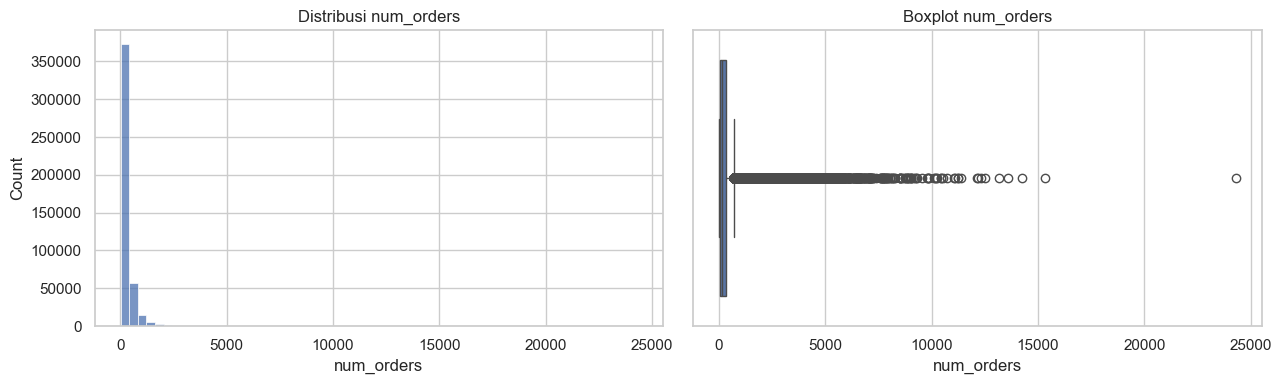

In [5]:
fig,ax=plt.subplots(1,2,figsize=(13,4))
sns.histplot(train_raw.num_orders,bins=60,ax=ax[0]); ax[0].set_title("Distribusi num_orders")
sns.boxplot(x=train_raw.num_orders,ax=ax[1]); ax[1].set_title("Boxplot num_orders")
plt.tight_layout(); plt.show()

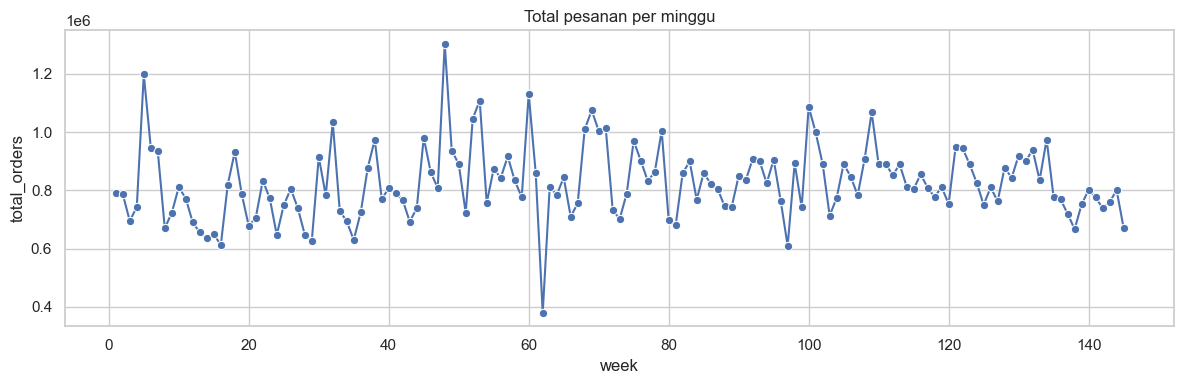

,week,total_orders,mean_orders
0,1,792261,271.136550
1,2,787084,271.783149
2,3,695262,239.828217
3,4,743529,257.365524
4,5,1198675,419.263729


In [6]:
weekly=train_raw.groupby("week",as_index=False).agg(total_orders=("num_orders","sum"),mean_orders=("num_orders","mean"))
plt.figure(figsize=(12,4)); sns.lineplot(data=weekly,x="week",y="total_orders",marker="o")
plt.title("Total pesanan per minggu"); plt.tight_layout(); plt.show()
display(weekly.head())

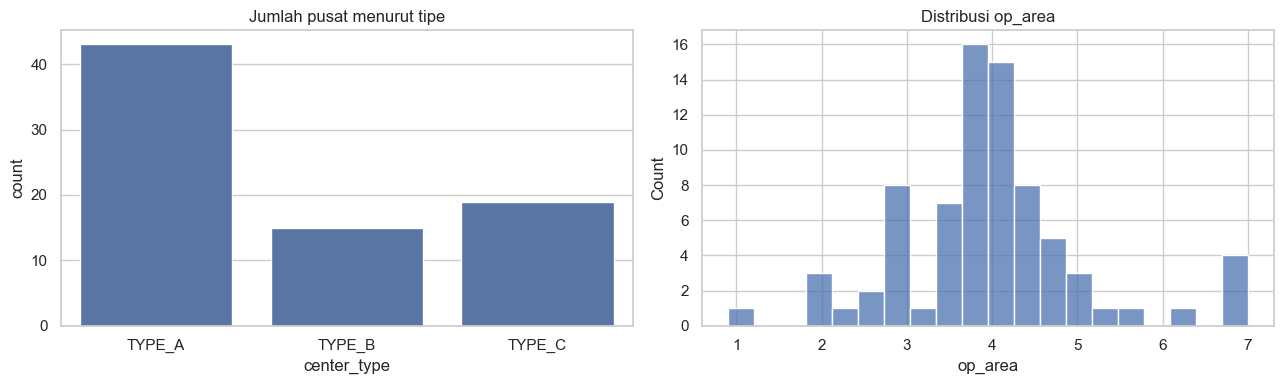

In [7]:
fig,ax=plt.subplots(1,2,figsize=(13,4))
sns.countplot(data=center_info,x="center_type",ax=ax[0]); ax[0].set_title("Jumlah pusat menurut tipe")
sns.histplot(data=center_info,x="op_area",bins=20,ax=ax[1]); ax[1].set_title("Distribusi op_area")
plt.tight_layout(); plt.show()

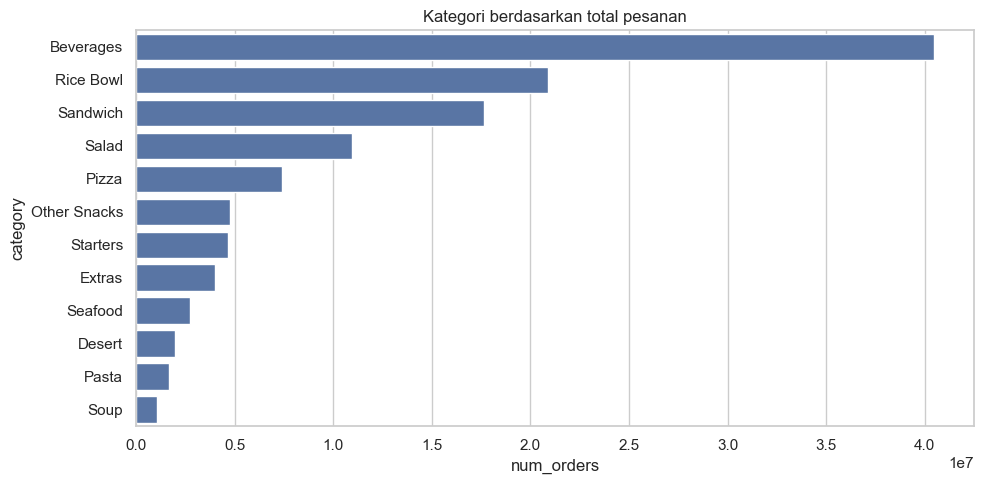

,category,num_orders
0,Beverages,40480525
8,Rice Bowl,20874063
10,Sandwich,17636782
9,Salad,10944336
7,Pizza,7383720
5,Other Snacks,4766293
13,Starters,4649122
3,Extras,3984979
11,Seafood,2715714
2,Desert,1940754


In [8]:
meal_eda=train_raw.merge(meal_info,on="meal_id",how="left")
cat=(meal_eda.groupby("category",as_index=False).num_orders.sum().sort_values("num_orders",ascending=False).head(12))
plt.figure(figsize=(10,5)); sns.barplot(data=cat,x="num_orders",y="category")
plt.title("Kategori berdasarkan total pesanan"); plt.tight_layout(); plt.show()
display(cat)

In [9]:
promo=train_raw.copy()
promo["promotion_flag"]=np.where((promo.emailer_for_promotion.fillna(0)==1)|(promo.homepage_featured.fillna(0)==1),"Ada promosi","Tanpa promosi")
display(promo.groupby("promotion_flag").num_orders.agg(["count","mean","median","sum"]))

,count,mean,median,sum
promotion_flag,,,,
Ada promosi,67674,551.805967,310.0,37342917
Tanpa promosi,388874,211.416983,122.0,82214568


**Catatan EDA:** pola dan perbedaan yang terlihat bersifat deskriptif, bukan bukti hubungan sebab-akibat. Nilai pesanan ekstrem tidak otomatis dihapus; pengaruhnya diperiksa melalui distribusi dan evaluasi model.

## 4. Data Preparation dan Feature Engineering

In [10]:
train=train_raw.drop_duplicates().copy()
centers=center_info.drop_duplicates(subset="center_id").copy()
meals=meal_info.drop_duplicates(subset="meal_id").copy()
for col in ["week","center_id","meal_id","checkout_price","base_price","emailer_for_promotion","homepage_featured","num_orders"]:
    train[col]=pd.to_numeric(train[col],errors="coerce")
centers["op_area"]=pd.to_numeric(centers["op_area"],errors="coerce")
data=train.merge(centers,on="center_id",how="left",validate="many_to_one")
data=data.merge(meals,on="meal_id",how="left",validate="many_to_one")
print("Ukuran setelah join:",data.shape)
display(data.head())
display(data.isna().sum().sort_values(ascending=False).to_frame("missing"))

Ukuran setelah join: (456548, 15)


,id,week,center_id,meal_id,checkout_price,base_price,emailer_for_promotion,homepage_featured,num_orders,city_code,region_code,center_type,op_area,category,cuisine
0,1379560,1,55,1885,136.83,152.29,0,0,177,647,56,TYPE_C,2.0,Beverages,Thai
1,1466964,1,55,1993,136.83,135.83,0,0,270,647,56,TYPE_C,2.0,Beverages,Thai
2,1346989,1,55,2539,134.86,135.86,0,0,189,647,56,TYPE_C,2.0,Beverages,Thai
3,1338232,1,55,2139,339.50,437.53,0,0,54,647,56,TYPE_C,2.0,Beverages,Indian
4,1448490,1,55,2631,243.50,242.50,0,0,40,647,56,TYPE_C,2.0,Beverages,Indian


,missing
id,0
week,0
center_id,0
meal_id,0
checkout_price,0
base_price,0
emailer_for_promotion,0
homepage_featured,0
num_orders,0
city_code,0


In [11]:
data=data.dropna(subset=["num_orders","week"]).copy()
data["week"]=data.week.astype(int)
data["week_squared"]=data.week**2
data["price_difference"]=data.checkout_price-data.base_price
data["price_ratio"]=np.where(data.base_price.ne(0),data.checkout_price/data.base_price,np.nan)
data["any_promotion"]=((data.emailer_for_promotion.fillna(0)==1)|(data.homepage_featured.fillna(0)==1)).astype(int)
print("Data siap:",data.shape)

Data siap: (456548, 19)


## 5. Feature Selection dan pembagian kronologis

Kolom `id` tidak digunakan karena hanya identifier. `center_id` dan `meal_id` diperlakukan sebagai kategori. Data dibagi berdasarkan urutan minggu, bukan random split, agar pengujian menggunakan periode yang lebih baru daripada pelatihan.

In [12]:
TARGET="num_orders"
cat_features=["center_id","meal_id","city_code","region_code","center_type","category","cuisine"]
num_features=["week","week_squared","checkout_price","base_price","price_difference","price_ratio","emailer_for_promotion","homepage_featured","any_promotion","op_area"]
features=cat_features+num_features
weeks=np.sort(data.week.unique())
split_week=weeks[max(1,int(len(weeks)*0.8))]
train_df=data[data.week<split_week].copy(); test_df=data[data.week>=split_week].copy()
X_train,y_train=train_df[features],train_df[TARGET]
X_test,y_test=test_df[features],test_df[TARGET]
print("Batas minggu:",split_week)
print("Train weeks:",train_df.week.min(),"-",train_df.week.max(),X_train.shape)
print("Test weeks:",test_df.week.min(),"-",test_df.week.max(),X_test.shape)
assert train_df.week.max()<test_df.week.min()

Batas minggu: 117
Train weeks: 1 - 116 (361348, 17)
Test weeks: 117 - 145 (95200, 17)


## 6. Modeling

In [1]:
numeric_pipe=Pipeline([("imputer",SimpleImputer(strategy="median")),("scale",StandardScaler())])
category_pipe=Pipeline([("imputer",SimpleImputer(strategy="most_frequent")),("onehot",OneHotEncoder(handle_unknown="ignore"))])
preprocess=ColumnTransformer([("num",numeric_pipe,num_features),("cat",category_pipe,cat_features)])
models={
 "Linear Regression":LinearRegression(),
 "Ridge Regression":Ridge(alpha=1.0),
 "Random Forest":RandomForestRegressor(n_estimators=150,min_samples_leaf=2,random_state=42,n_jobs=-1)
}
pipelines={name:Pipeline([("preprocess",preprocess),("model",est)]) for name,est in models.items()}
def metrics(y,p):
    return {"MAE":mean_absolute_error(y,p),"RMSE":np.sqrt(mean_squared_error(y,p)),"R2":r2_score(y,p)}
# Baseline pembanding: prediksi rata-rata target pada train
baseline=DummyRegressor(strategy="mean").fit(np.zeros((len(y_train),1)),y_train)
baseline_pred=baseline.predict(np.zeros((len(y_test),1)))
results={"Baseline mean":metrics(y_test,baseline_pred)}
predictions={}
for name,pipe in pipelines.items():
    print("Training",name)
    pipe.fit(X_train,y_train)
    predictions[name]=pipe.predict(X_test)
    results[name]=metrics(y_test,predictions[name])
results_df=pd.DataFrame(results).T.sort_values("RMSE")
display(results_df)

NameError: name 'Pipeline' is not defined

## 7. Evaluasi Linear Regression

In [ ]:
linear_model=pipelines["Linear Regression"]
linear_pred=predictions["Linear Regression"]
display(pd.DataFrame([metrics(y_test,linear_pred)],index=["Linear Regression"]))
comparison=pd.DataFrame({"actual":y_test.to_numpy(),"predicted":linear_pred},index=y_test.index)
comparison["residual"]=comparison.actual-comparison.predicted
comparison["absolute_error"]=comparison.residual.abs()
display(comparison.head(15))

NameError: name 'pipelines' is not defined

In [ ]:
plt.figure(figsize=(7,6)); sns.scatterplot(x=comparison.actual,y=comparison.predicted,alpha=.25)
lo=min(comparison.actual.min(),comparison.predicted.min()); hi=max(comparison.actual.max(),comparison.predicted.max())
plt.plot([lo,hi],[lo,hi],"--"); plt.xlabel("Aktual"); plt.ylabel("Prediksi")
plt.title("Aktual vs Prediksi — Linear Regression"); plt.tight_layout(); plt.show()

In [ ]:
fig,ax=plt.subplots(1,2,figsize=(13,4))
sns.histplot(comparison.residual,bins=60,kde=True,ax=ax[0]); ax[0].set_title("Distribusi residual")
sns.scatterplot(x=comparison.predicted,y=comparison.residual,alpha=.25,ax=ax[1]); ax[1].axhline(0,ls="--")
ax[1].set_title("Residual vs prediksi"); plt.tight_layout(); plt.show()

In [ ]:
weekly_test=test_df[["week"]].copy()
weekly_test["actual"]=y_test.to_numpy(); weekly_test["predicted"]=linear_pred
weekly_eval=weekly_test.groupby("week").apply(lambda g: pd.Series({
 "MAE":mean_absolute_error(g.actual,g.predicted),
 "RMSE":np.sqrt(mean_squared_error(g.actual,g.predicted)),
 "actual_mean":g.actual.mean(),"predicted_mean":g.predicted.mean(),"n":len(g)
}),include_groups=False).reset_index()
display(weekly_eval)
plt.figure(figsize=(11,4)); plt.plot(weekly_eval.week,weekly_eval.actual_mean,marker="o",label="Aktual")
plt.plot(weekly_eval.week,weekly_eval.predicted_mean,marker="o",label="Prediksi")
plt.title("Rata-rata aktual dan prediksi per minggu"); plt.legend(); plt.tight_layout(); plt.show()

### Panduan membaca metrik
- **MAE:** rata-rata kesalahan absolut dalam satuan jumlah pesanan; lebih kecil lebih baik.
- **RMSE:** memberi penalti lebih besar pada kesalahan besar; lebih kecil lebih baik.
- **R²:** proporsi variasi target yang dijelaskan model pada data uji; dapat bernilai negatif.
- Bandingkan hasil Linear Regression dengan baseline dan model pembanding. Laporkan hasil aktual, jangan mengarang angka sebelum notebook dijalankan.

In [ ]:
print("Linear Regression:")
for k,v in metrics(y_test,linear_pred).items(): print(f"{k}: {v:,.4f}")
print("RMSE terendah pada eksperimen:",results_df.index[0])

## 8. Simpan model dan hasil

In [ ]:
joblib.dump(linear_model,"linear_regression_food_demand.joblib")
comparison.to_csv("hasil_prediksi_linear_regression.csv",index=False)
results_df.to_csv("perbandingan_model.csv")
print("Model dan tabel hasil berhasil disimpan.")

## 9. Kesimpulan dan rekomendasi


**Keterbatasan:** `week` merupakan indeks minggu tanpa tanggal kalender eksplisit; evaluasi menggunakan satu pemisahan kronologis; performa model dipengaruhi pola data historis dan fitur yang tersedia. Perbedaan deskriptif promosi/kategori tidak boleh ditafsirkan sebagai kausalitas.